# Week 3 Day 4: UMAP, in Colab

In today's lesson you drew 64 columns in two with **t-SNE**, in your browser. This notebook does the same job with a second tool, **UMAP**, and shows the one thing UMAP can do that t-SNE cannot: place parcels, digits or accounts it has never seen on a picture it has already drawn. It takes about 15 minutes.

**Why Colab.** The lesson's code runs in your browser. UMAP is built on a library called numba, which has no version that runs there, so it runs here instead, on a computer Google lends you. Press **Runtime → Run all**, or run the cells one by one with Shift+Enter. If you have no Google account, you can still read this notebook on GitHub with every output already printed.

**What you need from the lesson.** A picture in two dimensions is useful when points that were close in all the columns stay close in the picture. The lesson measured that with one number: for each point, do its 5 nearest neighbours in the picture share its label? On the lesson's 1,000 digits, PCA's picture scored about 0.56 and t-SNE's about 0.94. This notebook uses all 1,797 digits, so its figures come out a little higher.

In [1]:
%pip install -q umap-learn==0.6.0

import umap, sklearn, pandas, numpy
print("umap-learn", umap.__version__)
print("scikit-learn", sklearn.__version__)
print("pandas", pandas.__version__)
print("numpy", numpy.__version__)

umap-learn 0.6.0
scikit-learn 1.9.1
pandas 3.1.1
numpy 2.5.5


The first line installs umap-learn 0.6.0, the version this notebook was written for. Colab already has pandas and scikit-learn.

The saved run printed umap-learn 0.6.0, scikit-learn 1.9.1, pandas 3.1.1 and numpy 2.5.5. Colab's own versions may differ, and UMAP's picture depends on them, so your figures can differ a little from the ones quoted below. The conclusions should not.

## 1. The digits again

The same 1,797 handwritten digits as the lesson: each is 64 numbers, one for each pixel of an 8 × 8 image. The helper `neighbours` is the lesson's score: the share of points whose 5 nearest neighbours in a picture carry the same digit, checked on five held-out parts.

In [2]:
import time
import warnings
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score

warnings.filterwarnings("ignore")  # UMAP prints notes about future versions that do not matter here
digits = load_digits()
X, y = digits.data, digits.target

def neighbours(picture, labels):
    return round(float(cross_val_score(KNeighborsClassifier(5), picture, labels, cv=5).mean()), 3)

print(X.shape, "all 64 columns:", neighbours(X, y))

(1797, 64) all 64 columns: 0.963


In all 64 columns, a digit's nearest neighbours are the same digit 0.963 of the time. That is the figure a perfect picture would keep. A picture has only two columns to do it with.

## 2. Three pictures of the same digits

Before you run the cell: UMAP and t-SNE both try to keep neighbours together. Do you expect UMAP's score to be nearer PCA's or nearer t-SNE's? And which of the three will be slowest? Decide, then run it.

PCA 0.603 0.0 seconds


t-SNE 0.976 1.8 seconds


UMAP 0.983 4.5 seconds


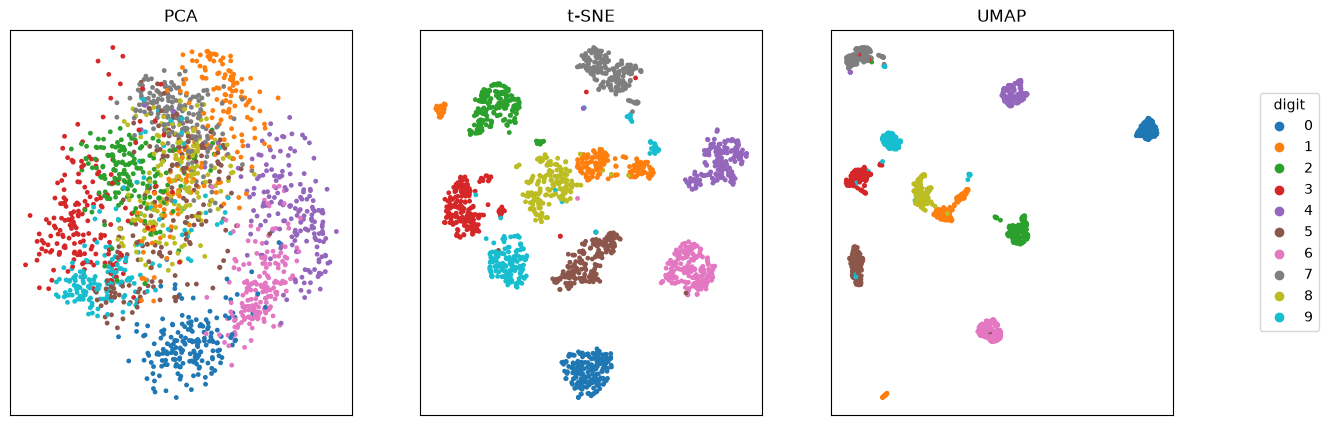

In [3]:
pictures = {}
for name, maker in [("PCA", PCA(n_components=2)),
                    ("t-SNE", TSNE(n_components=2, init="pca", perplexity=30, random_state=0)),
                    ("UMAP", umap.UMAP(n_components=2, n_neighbors=15, random_state=0))]:
    start = time.perf_counter()
    pictures[name] = maker.fit_transform(X)
    print(name, neighbours(pictures[name], y), round(time.perf_counter() - start, 1), "seconds")

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (name, p) in zip(axes, pictures.items()):
    points = ax.scatter(p[:, 0], p[:, 1], c=y, cmap="tab10", s=6)
    ax.set_title(name)
    ax.set_xticks([]); ax.set_yticks([])
fig.legend(*points.legend_elements(), title="digit", loc="center right")
plt.show()

UMAP keeps neighbours together as well as t-SNE does: 0.983 against t-SNE's 0.976, and far above PCA's 0.603. In the pictures, PCA smears the ten digits over each other, while t-SNE and UMAP each draw ten separate islands.

UMAP was the slowest of the three here, by a few seconds. Most of that is numba compiling UMAP's code the first time it is used; the next cell's UMAP runs are quicker, as their times show.

**What the pictures do not tell you.** The same warning as for t-SNE applies to UMAP. The islands are real: points in one island are neighbours in the 64 columns. But the size of an island, and how far one island sits from another, are not measurements. Do not read "the 4s are twice as spread out as the 0s" or "7 is close to 1" off either picture without checking it in the original columns.

## 3. UMAP's main setting

t-SNE has `perplexity`. UMAP's version is `n_neighbors`: how many nearby points each point looks at when the picture is built. A small number looks only at very local structure; a large number looks at more of the whole.

Will the score change much between 5, 15 and 50 neighbours? Guess, then run it.

5 neighbours: 0.982 0.8 seconds


15 neighbours: 0.983 1.2 seconds


50 neighbours: 0.974 1.8 seconds


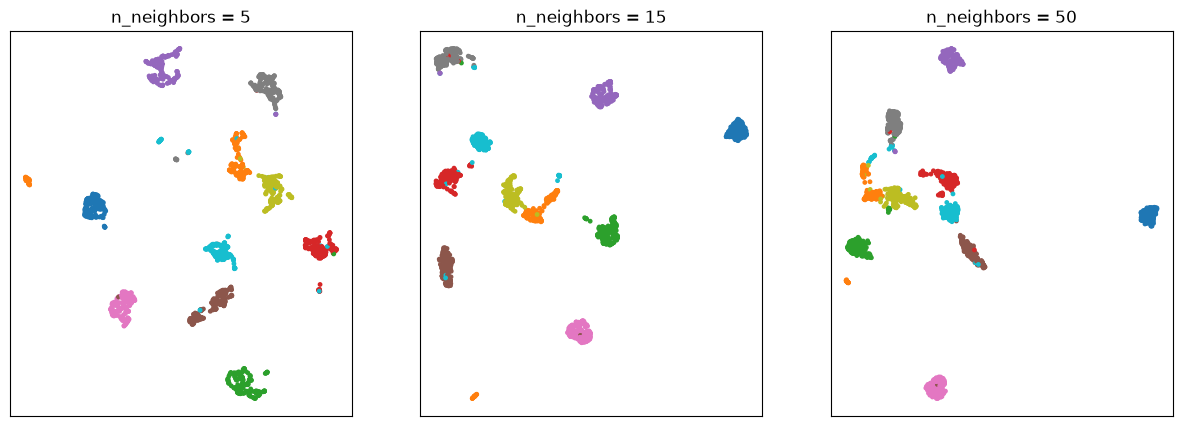

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, k in zip(axes, [5, 15, 50]):
    start = time.perf_counter()
    p = umap.UMAP(n_neighbors=k, random_state=0).fit_transform(X)
    print(k, "neighbours:", neighbours(p, y), round(time.perf_counter() - start, 1), "seconds")
    ax.scatter(p[:, 0], p[:, 1], c=y, cmap="tab10", s=6)
    ax.set_title(f"n_neighbors = {k}")
    ax.set_xticks([]); ax.set_yticks([])
plt.show()

The score barely moves: 0.982, 0.983 and 0.974. The pictures do change: with 5 neighbours the islands break into smaller pieces, and with 50 they are rounder and closer together. So the setting changes how the picture looks more than what it keeps. That is one more reason not to read meaning into an island's shape.

Look at the seconds too: each run is quicker than the first UMAP run above, because the compiling was done there.

## 4. What UMAP can do that t-SNE cannot

Suppose the client sends 797 new digits next month. With t-SNE you would have to draw the whole picture again, and every island could land somewhere new. UMAP learns a map: once fitted, it has a `transform` that places new points on the picture it already drew.

The cell fits UMAP on the first 1,000 digits only, then places the other 797. Will the new digits land on the right islands? The score answers it: a k-nearest-neighbours model learns the islands from the 1,000 and is asked to name the 797 from where they landed.

new digits named correctly from where they landed: 0.954


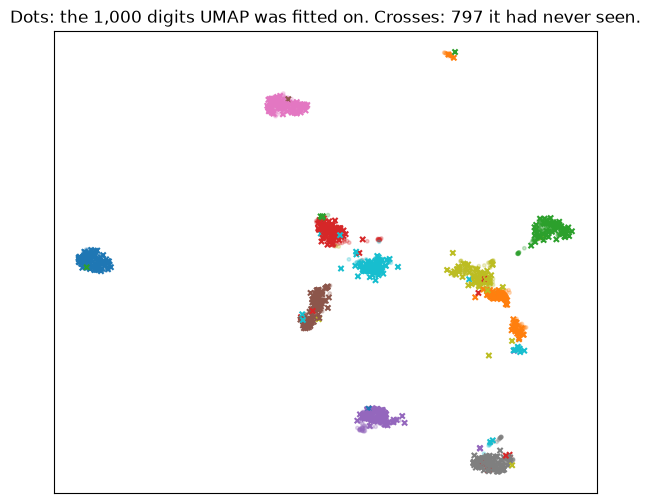

t-SNE: 'TSNE' object has no attribute 'transform'


In [5]:
mapper = umap.UMAP(n_neighbors=15, random_state=0).fit(X[:1000])
old = mapper.embedding_
new = mapper.transform(X[1000:])
judge = KNeighborsClassifier(5).fit(old, y[:1000])
print("new digits named correctly from where they landed:", round(float(judge.score(new, y[1000:])), 3))

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(old[:, 0], old[:, 1], c=y[:1000], cmap="tab10", s=6, alpha=0.25)
ax.scatter(new[:, 0], new[:, 1], c=y[1000:], cmap="tab10", s=14, marker="x")
ax.set_title("Dots: the 1,000 digits UMAP was fitted on. Crosses: 797 it had never seen.")
ax.set_xticks([]); ax.set_yticks([])
plt.show()
try:
    TSNE().transform(X[1000:])
except AttributeError as error:
    print("t-SNE:", error)

The new digits land on the right islands: 0.954 of them are named correctly from their position alone. t-SNE has no `transform` at all, as the last line shows.

This is the practical difference between the two. For a one-off picture of a fixed table, either will do. If the picture has to be used again, on new rows, or as columns for a model inside a pipeline, UMAP can do it and t-SNE cannot. It also means UMAP must be fitted on the training rows only, like any other preparation step.

## 5. The client's accounts

Now the same tool on the table you clustered in the lesson: one row for each of the client's accounts, with four columns that describe how the account ships. The cell rebuilds that table from the client's two files, exactly as the lesson did, and fits the lesson's K-Means with 3 groups.

Four columns is very few. Do you expect UMAP's picture to show the three groups better than PCA's? Decide, then run it.

In [6]:
import os
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Set the environment variable DATA_DIR to a folder holding the two files to read them from there instead of GitHub.
DATA_DIR = os.environ.get("DATA_DIR")
BASE = "https://raw.githubusercontent.com/talhaturab/fde-course-notebooks/main/data/"

def data_file(name):
    return os.path.join(DATA_DIR, name) if DATA_DIR else BASE + name

history = pd.read_csv(data_file("shipments_history.csv"))
accounts = pd.read_csv(data_file("customers_history.csv"))
history["when"] = pd.to_datetime(history["dispatched_at"])
first = history.groupby("customer_id")["when"].min()
window = history[(history["when"] >= "2024-10-01") & (history["when"] < "2026-10-01")].copy()
window["nov_dec"] = window["when"].dt.month.isin([11, 12])
window["litres_per_kg"] = window["volume_l"] / window["weight_kg"]
window["month"] = window["when"].dt.to_period("M")
by = window.groupby("customer_id")
table = pd.DataFrame({"parcels": by.size(), "months": by["month"].nunique(), "weight": by["weight_kg"].median(),
                      "litres_per_kg": by["litres_per_kg"].median(), "nov_dec_share": by["nov_dec"].mean()})
table = table[(table["parcels"] >= 20) & (first.reindex(table.index) < "2025-11-01")]
table["log_per_month"] = np.log10(table["parcels"] / table["months"])
table["log_weight"] = np.log10(table["weight"])
table["log_litres_per_kg"] = np.log10(table["litres_per_kg"])
columns = ["log_per_month", "log_weight", "log_litres_per_kg", "nov_dec_share"]
scaled = StandardScaler().fit_transform(table[columns])
groups = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(scaled)
print(len(table), "accounts;", "group sizes", np.bincount(groups))

167 accounts; group sizes [87 57 23]


PCA 0.934
UMAP 0.964


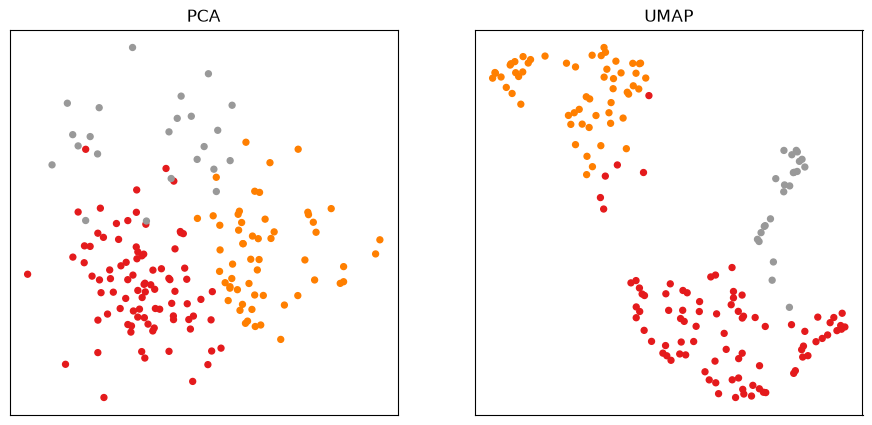

share of the spread PCA's two components keep: 0.683


In [7]:
flat = {"PCA": PCA(n_components=2).fit_transform(scaled),
        "UMAP": umap.UMAP(n_neighbors=15, random_state=0).fit_transform(scaled)}
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, (name, p) in zip(axes, flat.items()):
    print(name, neighbours(p, groups))
    ax.scatter(p[:, 0], p[:, 1], c=groups, cmap="Set1", s=18)
    ax.set_title(name)
    ax.set_xticks([]); ax.set_yticks([])
plt.show()
print("share of the spread PCA's two components keep:", round(float(PCA(n_components=2).fit(scaled).explained_variance_ratio_.sum()), 3))

The table holds 167 accounts, the same as the lesson's. PCA's picture already keeps the groups together: 0.934. UMAP's is a little higher, 0.964. PCA's two components hold 0.683 of the spread of four columns, so there was little left for a cleverer tool to rescue.

That is the honest conclusion for this client. UMAP and t-SNE earn their place when a table has tens or hundreds of columns, like the digits' 64 pixels, or the text and image columns that Week 4 brings. For a table of four columns, a scatter plot or PCA is simpler, and a PCA axis can still be named from its loadings (Week 2 Day 5), which a UMAP axis cannot.

## What to keep

- UMAP, like t-SNE, draws many columns in two and keeps neighbours together. On all 1,797 digits both score about 0.98, against 0.6 for PCA.
- Islands are real. Their sizes, and the distances between them, are not measurements.
- `n_neighbors` changes how the picture looks more than what it keeps.
- UMAP can `transform` new rows onto an old picture. t-SNE cannot.
- With few columns, PCA is enough.